# 결론 8 — H3 다시 짜기 (서울 전체 일반 가설)

`report_09`의 H3(관악 vs 나머지 24개 구)는 **관악을 방향 공백 순위 1위라서 고른 뒤 같은 지표로 검정**했다.
**선택 편향**이다. 그래서 H3을 **서울 전체 일반 가설**로 다시 세우고, 관악은 **기술 통계(순위)로만** 쓴다.

**새 H3**: 걸어서(300m) 닿는 멀리 가는 노선 수가 **같은 정류장끼리** 비교해도,
**의존 정류장**은 출근 1위 목적지행 노선이 걸어서도 없는 비율(**방향 공백**)이 더 높은가

- **귀무**: 노선 수가 같으면 의존·비의존의 방향 공백 비율은 같다
- **대립**: **의존이 더 높다**
- **메인 검정**: 도보 300m 멀리노선수 층(0~2, 3~5, 6~9, 10+)별 2×2 +
  **Mantel-Haenszel**(층 합친 검정, `statsmodels` StratifiedTable)
- 결과가 유의하지 않으면 **"기각 못 함"으로 그대로 적는다.**

**의존 정류장** = 자기 정류장 멀리 가는 노선 **≤1개** (+ 대상 조건) = `d300`
**방향 공백** = 도보 300m 안에 자기 구 출근 1위 목적지 구를 지나는 멀리 가는 노선이 **0개** (con_5_gap25와 같음)

In [1]:
# 프로젝트 ROOT 찾아서 공통 경로·함수 불러오기 (경로 문자열은 src/paths.py에만)
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from paths import RAW, EXT, PROC, REPORTS

print("ROOT:", ROOT)

ROOT: C:\study\aix\aix_2


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.stats.contingency_tables import StratifiedTable

import biv_stats as bs
from bus_util import ARS2GU, FAR, GU_ORDER, P75, haversine_m

mpl.rcParams["font.family"] = "Malgun Gothic"
mpl.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Malgun Gothic", rc={"axes.unicode_minus": False})
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 250)

HL = "관악구"
RS = [200, 300, 500]
R_MAIN = 300
BANDS = [(0, 2, "0~2"), (3, 5, "3~5"), (6, 9, "6~9"), (10, 10 ** 6, "10+")]

stop = pd.read_csv(PROC / "stop_metrics_subway.csv", encoding="utf-8-sig",
                   dtype={"버스정류장ARS번호": str})
sr = pd.read_csv(PROC / "stop_route.csv", encoding="utf-8-sig",
                 dtype={"ARS": str, "노선번호": str})
order = pd.read_csv(PROC / "route_order.csv", encoding="utf-8-sig",
                    dtype={"ARS": str, "노선번호": str})
pairs = pd.read_csv(PROC / "fin_h3_pairs.csv", encoding="utf-8-sig")
prev = pd.read_csv(PROC / "fin_h3gap_stops.csv", encoding="utf-8-sig",
                   dtype={"ARS": str})
gap25 = pd.read_csv(PROC / "fin_gap25.csv", encoding="utf-8-sig").set_index("자치구")
print(stop.shape, sr.shape, order.shape, pairs.shape, prev.shape)

(10615, 24) (33992, 7) (37694, 6) (600, 13) (1489, 8)


In [3]:
# con_5_gap25·con_7과 같은 전처리: 좌표 · 정류장별 멀리 가는 노선 집합 · 구별 경유 노선 집합
attr = (stop.rename(columns={"버스정류장ARS번호": "ARS", "월승차": "정류장월승차"})
        [["ARS", "정류장명", "자치구", "정류장월승차", "멀리가는노선수",
          "가까운역거리m", "경도", "위도"]].copy())
cod = attr.dropna(subset=["위도", "경도"]).reset_index(drop=True)
lat = cod["위도"].to_numpy(float)
lon = cod["경도"].to_numpy(float)
ars = cod["ARS"].to_numpy()
pos = {a: i for i, a in enumerate(ars)}

fset = sr[sr["노선종류"].isin(FAR)].groupby("ARS")["노선번호"].apply(frozenset)
rsets = [fset.get(a, frozenset()) for a in ars]

far_type = sr.drop_duplicates("노선번호").set_index("노선번호")["노선종류"]
ro = order.assign(자치구=order["ARS"].str[:2].map(ARS2GU))
rgu = (ro[ro["노선번호"].isin(far_type[far_type.isin(FAR)].index)]
       .groupby("노선번호")["자치구"].apply(lambda s: frozenset(s.dropna())))
passes = {g: {r for r, s in rgu.items() if g in s} for g in GU_ORDER}
print("좌표 있는 정류장:", len(cod), "/ 멀리 가는 노선:", len(rgu))

좌표 있는 정류장: 10606 / 멀리 가는 노선: 343


## 1. 대상 정류장 · 의존 여부 · 방향 공백

`fin_h3_pairs.csv` 재사용 — 도착 **7~9시** · 평일 · 이동유형 **HW(집→직장)** · 출발≠도착.

In [4]:
rows = []
for g in GU_ORDER:
    d = (pairs[pairs["출발구"] == g].set_index("도착구")["이동인구"]
         .sort_values(ascending=False))
    tot = d.sum()
    rec = {"자치구": g}
    for k in range(3):
        rec[f"{k + 1}위"] = d.index[k]
        rec[f"{k + 1}위비중"] = d.iloc[k] / tot
    rows.append(rec)
dest = pd.DataFrame(rows).set_index("자치구")
print(f"{HL} 출근 1위 = {dest.loc[HL, '1위']} ({dest.loc[HL, '1위비중']:.1%})")

관악구 출근 1위 = 강남구 (22.6%)


In [5]:
# 대상(승차 >= P75 + 역 300m 밖) + 반경별 도보권 멀리 가는 노선 합집합 + 공백 0/1
tgt = cod[(cod["정류장월승차"] >= P75) & (cod["가까운역거리m"] > 300)].copy()
uni = {R: [] for R in RS}
for a in tgt["ARS"]:
    i = pos[a]
    d = haversine_m(lat[i], lon[i], lat, lon)
    for R in RS:
        uni[R].append(frozenset().union(*[rsets[j] for j in np.flatnonzero(d <= R)]))
for R in RS:
    tgt[f"도보{R}_노선수"] = [len(u) for u in uni[R]]
    tgt[f"공백_{R}"] = [int(len(u & passes[dest.loc[gu, "1위"]]) == 0)
                      for gu, u in zip(tgt["자치구"], uni[R])]

# 목적지 1~3위 비중 가중 공백 (0~1 연속값)
w_vals = []
for gu, u in zip(tgt["자치구"], uni[R_MAIN]):
    ws = np.array([dest.loc[gu, f"{k}위비중"] for k in [1, 2, 3]], float)
    gs = np.array([int(len(u & passes[dest.loc[gu, f"{k}위"]]) == 0) for k in [1, 2, 3]])
    w_vals.append(float((ws * gs).sum() / ws.sum()))
tgt["공백_가중"] = w_vals

# 의존 여부 = 자기 정류장 멀리 가는 노선 <=1 (d300 정의)
tgt["의존"] = (tgt["멀리가는노선수"] <= 1).astype(int)
print(f"대상 정류장 {len(tgt)}개 → 의존 {int(tgt['의존'].sum())} / "
      f"비의존 {int((1 - tgt['의존']).sum())}")

# report_09 저장본과 공백 값이 같은지 확인
chk = tgt.merge(prev[["ARS", "공백"]], on="ARS", how="inner")
print(f"report_09 저장본과 공백 일치: {int((chk['공백_300'] == chk['공백']).sum())}"
      f"/{len(chk)}")

대상 정류장 1489개 → 의존 155 / 비의존 1334
report_09 저장본과 공백 일치: 1489/1489


## 2. 참고 — 층을 안 나눈 전체 비교

**이 값은 노선 수 함정이 섞여 있다.** 의존 정류장은 자기 정류장에 멀리 가는 노선이 ≤1개라
도보권 노선 수도 적은 쪽으로 쏠린다. 그래서 층을 나눈 3절이 메인이다.

In [6]:
# 2x2 공백 비율 검정. 기대빈도 5 미만 칸이 있으면 Fisher
def chi_2x2(a_gap, a_n, b_gap, b_n):
    tbl = np.array([[a_gap, a_n - a_gap], [b_gap, b_n - b_gap]])
    out = {"n_의존": a_n, "n_비의존": b_n,
           "공백_의존": round(a_gap / a_n, 3) if a_n else np.nan,
           "공백_비의존": round(b_gap / b_n, 3) if b_n else np.nan}
    if a_n == 0 or b_n == 0 or tbl.sum(0).min() == 0:
        out.update({"방법": "계산 불가", "p표시": "-", "별표": "-", "유의": False})
        return out
    chi2, p_chi, dof, exp = stats.chi2_contingency(tbl, correction=False)
    small = int((exp < 5).sum())
    method, p = (("Fisher 정확검정", stats.fisher_exact(tbl)[1]) if small
                 else ("카이제곱", p_chi))
    out.update({"방법": method, "기대빈도5미만칸": small, "p표시": bs.ptxt(p),
                "별표": bs.star(p) or "n.s.", "유의": p < 0.05})
    return out


D = tgt[tgt["의존"] == 1]
N = tgt[tgt["의존"] == 0]
pooled = chi_2x2(int(D["공백_300"].sum()), len(D),
                 int(N["공백_300"].sum()), len(N))
print("[참고 — 노선 수 함정 섞인 값]")
print(f"의존 {int(D['공백_300'].sum())}/{len(D)} = {D['공백_300'].mean():.3f}  vs  "
      f"비의존 {int(N['공백_300'].sum())}/{len(N)} = {N['공백_300'].mean():.3f}")
print(f"{pooled['방법']} → {pooled['p표시']} {pooled['별표']}")
print(f"\n도보 300m 멀리노선수 중앙값: 의존 {D['도보300_노선수'].median():.0f} vs "
      f"비의존 {N['도보300_노선수'].median():.0f}  ← 함정 (층을 나눠야 한다)")

[참고 — 노선 수 함정 섞인 값]
의존 77/155 = 0.497  vs  비의존 172/1334 = 0.129
카이제곱 → p<0.05 **

도보 300m 멀리노선수 중앙값: 의존 2 vs 비의존 8  ← 함정 (층을 나눠야 한다)


## 3. 메인 — 층별 2×2 + Mantel-Haenszel

층 = **도보 R 안 멀리 가는 노선 수** 구간. 층 안에서 노선 수가 비슷한 정류장끼리만 비교한다.
어느 한쪽 **n<10**이면 판단 보류(검정은 하지 않고 비율만 적는다).

In [7]:
# 층별 의존 vs 비의존 공백 비율 + 검정 → (표, MH에 넣을 2x2 리스트)
def layer_tbl(df, R):
    col, gcol = f"도보{R}_노선수", f"공백_{R}"
    rows, tabs = [], []
    for lo, hi, lab in BANDS:
        s = df[(df[col] >= lo) & (df[col] <= hi)]
        a, b = s[s["의존"] == 1], s[s["의존"] == 0]
        r = {"층(도보노선수)": lab}
        r.update(chi_2x2(int(a[gcol].sum()), len(a), int(b[gcol].sum()), len(b)))
        if len(a) < 10 or len(b) < 10:
            r.update({"방법": "n<10 판단 보류", "p표시": "-", "별표": "-"})
        rows.append(r)
        if len(a) and len(b):
            tabs.append(np.array([[int(a[gcol].sum()), len(a) - int(a[gcol].sum())],
                                  [int(b[gcol].sum()), len(b) - int(b[gcol].sum())]]))
    keep = ["층(도보노선수)", "n_의존", "n_비의존", "공백_의존", "공백_비의존",
            "방법", "p표시", "별표"]
    return pd.DataFrame(rows)[keep], tabs


# Mantel-Haenszel 공통 오즈비 + 층 합친 검정 + Breslow-Day 동질성
def mh(tabs):
    st = StratifiedTable([t.astype(float) for t in tabs])
    orp = float(st.oddsratio_pooled)
    p_mh = float(st.test_null_odds().pvalue)
    try:
        p_bd = float(st.test_equal_odds().pvalue)
        bd = f"{bs.ptxt(p_bd)} {bs.star(p_bd) or 'n.s.'}"
    except Exception as e:
        bd = f"계산 불가 ({type(e).__name__})"
    return {"층수": len(tabs), "MH 공통오즈비": round(orp, 3),
            "p표시": bs.ptxt(p_mh), "별표": bs.star(p_mh) or "n.s.",
            "유의": p_mh < 0.05, "Breslow-Day(동질성)": bd}


layer300, tabs300 = layer_tbl(tgt, R_MAIN)
layer300

,층(도보노선수),n_의존,n_비의존,공백_의존,공백_비의존,방법,p표시,별표
0,0~2,80,36,0.700,0.444,카이제곱,p<0.05,**
1,3~5,31,294,0.323,0.153,카이제곱,p<0.05,*
2,6~9,21,448,0.286,0.096,Fisher 정확검정,p<0.05,*
3,10+,23,556,0.217,0.122,Fisher 정확검정,p>0.05,n.s.


In [8]:
mh300 = mh(tabs300)
print("[메인] Mantel-Haenszel — 도보 300m 노선수 층 4개를 합친 검정")
for k, v in mh300.items():
    print(f"  {k}: {v}")
print(f"\n→ 공통 오즈비 {mh300['MH 공통오즈비']} "
      f"({'의존 쪽 공백 오즈가 더 크다' if mh300['MH 공통오즈비'] > 1 else '의존 쪽이 더 작다'}), "
      f"{mh300['p표시']} {mh300['별표']}")
print(f"→ 결론: 귀무가설 {'기각' if mh300['유의'] else '기각 못 함'}")

[메인] Mantel-Haenszel — 도보 300m 노선수 층 4개를 합친 검정
  층수: 4
  MH 공통오즈비: 2.752
  p표시: p<0.05
  별표: **
  유의: True
  Breslow-Day(동질성): p>0.05 n.s.

→ 공통 오즈비 2.752 (의존 쪽 공백 오즈가 더 크다), p<0.05 **
→ 결론: 귀무가설 기각


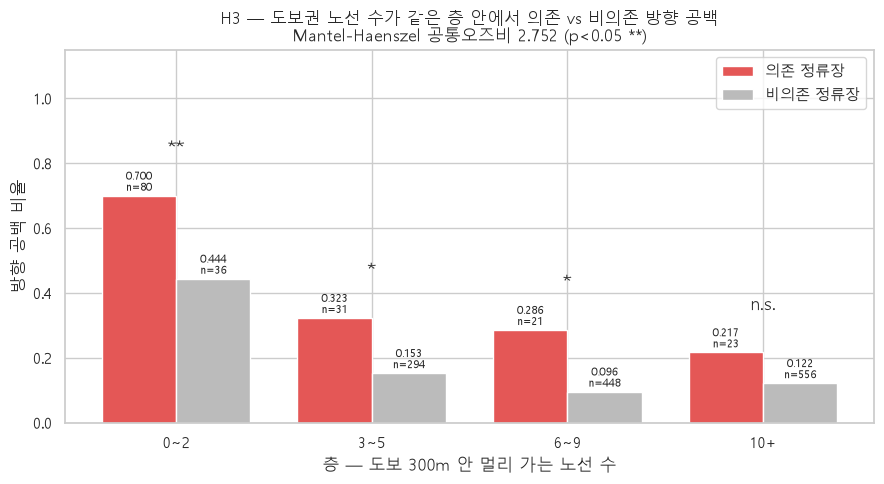

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(layer300))
w = 0.38
ax.bar(x - w / 2, layer300["공백_의존"], w, color="#E45756", label="의존 정류장")
ax.bar(x + w / 2, layer300["공백_비의존"], w, color="#bbbbbb", label="비의존 정류장")
for i, r in layer300.iterrows():
    for off, c, n in [(-w / 2, "공백_의존", "n_의존"), (w / 2, "공백_비의존", "n_비의존")]:
        if pd.notna(r[c]):
            ax.text(i + off, r[c] + 0.015, f"{r[c]:.3f}\nn={r[n]}", ha="center",
                    fontsize=8)
    top = np.nanmax([r["공백_의존"], r["공백_비의존"]]) + 0.13
    ax.text(i, top, r["별표"], ha="center", fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(layer300["층(도보노선수)"])
ax.set_xlabel("층 — 도보 300m 안 멀리 가는 노선 수")
ax.set_ylabel("방향 공백 비율")
ax.set_ylim(0, 1.15)
ax.set_title(f"H3 — 도보권 노선 수가 같은 층 안에서 의존 vs 비의존 방향 공백\n"
             f"Mantel-Haenszel 공통오즈비 {mh300['MH 공통오즈비']} "
             f"({mh300['p표시']} {mh300['별표']})")
ax.legend()
plt.tight_layout()
plt.show()

## 4. 견고성

1) 반경 **200m·500m** (층 기준 노선 수도 그 반경) / 2) **1~3위 비중 가중** 공백 층별 순위합 검정(W)
3) **관악 제외** / 4) **의존 비율 상위 5개 구 제외**

In [10]:
# (1) 반경 200·500m에서 층별 + MH 반복
rob = []
layers = {}
for R in RS:
    lt, tb = layer_tbl(tgt, R)
    layers[f"반경 {R}m"] = lt
    m = mh(tb)
    rob.append({"버전": f"반경 {R}m" + (" (메인)" if R == R_MAIN else ""),
                "공백_의존": round(float(tgt.loc[tgt["의존"] == 1, f"공백_{R}"].mean()), 3),
                "공백_비의존": round(float(tgt.loc[tgt["의존"] == 0, f"공백_{R}"].mean()), 3),
                "검정": f"MH (층 {m['층수']}개)", "MH 공통오즈비": m["MH 공통오즈비"],
                "p표시": m["p표시"], "별표": m["별표"]})
for k, v in layers.items():
    print(f"\n[{k}]")
    print(v.to_string(index=False))


[반경 200m]
층(도보노선수)  n_의존  n_비의존  공백_의존  공백_비의존          방법    p표시   별표
     0~2   107     57  0.748   0.439        카이제곱 p<0.05   **
     3~5    23    407  0.304   0.172 Fisher 정확검정 p>0.05 n.s.
     6~9    14    443  0.357   0.115 Fisher 정확검정 p<0.05    *
     10+    11    427  0.182   0.157 Fisher 정확검정 p>0.05 n.s.

[반경 300m]
층(도보노선수)  n_의존  n_비의존  공백_의존  공백_비의존          방법    p표시   별표
     0~2    80     36  0.700   0.444        카이제곱 p<0.05   **
     3~5    31    294  0.323   0.153        카이제곱 p<0.05    *
     6~9    21    448  0.286   0.096 Fisher 정확검정 p<0.05    *
     10+    23    556  0.217   0.122 Fisher 정확검정 p>0.05 n.s.

[반경 500m]
층(도보노선수)  n_의존  n_비의존  공백_의존  공백_비의존          방법    p표시   별표
     0~2    35     10  0.514   0.600 Fisher 정확검정 p>0.05 n.s.
     3~5    32    118  0.312   0.153        카이제곱 p<0.05    *
     6~9    27    312  0.148   0.099 Fisher 정확검정 p>0.05 n.s.
     10+    61    894  0.213   0.078        카이제곱 p<0.05   **


In [11]:
# (2) 1~3위 비중 가중 공백 — 층별 의존 vs 비의존 순위합 검정(W)
rows = []
for lo, hi, lab in BANDS:
    s = tgt[(tgt["도보300_노선수"] >= lo) & (tgt["도보300_노선수"] <= hi)]
    a = s.loc[s["의존"] == 1, "공백_가중"]
    b = s.loc[s["의존"] == 0, "공백_가중"]
    rec = {"층(도보300m 노선수)": lab, "n_의존": len(a), "n_비의존": len(b),
           "평균_의존": round(float(a.mean()), 3) if len(a) else np.nan,
           "평균_비의존": round(float(b.mean()), 3) if len(b) else np.nan}
    if len(a) >= 10 and len(b) >= 10:
        g = bs.group2(a, b, "의존", "비의존", "가중 공백")
        rec.update({"중앙값_의존": g["중앙값_의존"], "중앙값_비의존": g["중앙값_비의존"],
                    "방법": g["방법"], "p표시": g["p표시"], "별표": g["별표"] or "n.s."})
    else:
        rec.update({"중앙값_의존": np.nan, "중앙값_비의존": np.nan,
                    "방법": "n<10 판단 보류", "p표시": "-", "별표": "-"})
    rows.append(rec)
layer_w = pd.DataFrame(rows)
gw = bs.group2(tgt.loc[tgt["의존"] == 1, "공백_가중"],
               tgt.loc[tgt["의존"] == 0, "공백_가중"], "의존", "비의존", "가중 공백")
rob.append({"버전": "1~3위 비중 가중 (층별 순위합)",
            "공백_의존": gw["평균_의존"], "공백_비의존": gw["평균_비의존"],
            "검정": f"순위합 검정(W) 층별 — 유의 층 "
                   f"{int((layer_w['p표시'] == 'p<0.05').sum())}/"
                   f"{int((layer_w['p표시'] != '-').sum())}",
            "MH 공통오즈비": np.nan,
            "p표시": "-", "별표": "-"})
layer_w

,층(도보300m 노선수),n_의존,n_비의존,평균_의존,평균_비의존,중앙값_의존,중앙값_비의존,방법,p표시,별표
0,0~2,80,36,0.747,0.476,1.0000,0.4162,순위합 검정(W),p<0.05,**
1,3~5,31,294,0.324,0.200,0.2534,0.1598,순위합 검정(W),p>0.05,n.s.
2,6~9,21,448,0.218,0.110,0.0000,0.0000,순위합 검정(W),p>0.05,n.s.
3,10+,23,556,0.117,0.084,0.0000,0.0000,순위합 검정(W),p>0.05,n.s.


In [12]:
# (3) 관악 제외 / (4) 의존 비율 상위 5개 구 제외
TOP5 = ["관악구", "금천구", "동작구", "도봉구", "양천구"]
for lab, drop in [("관악 제외", [HL]), ("의존 비율 상위 5개 구 제외", TOP5)]:
    sub = tgt[~tgt["자치구"].isin(drop)]
    lt, tb = layer_tbl(sub, R_MAIN)
    m = mh(tb)
    layers[lab] = lt
    rob.append({"버전": lab,
                "공백_의존": round(float(sub.loc[sub["의존"] == 1, "공백_300"].mean()), 3),
                "공백_비의존": round(float(sub.loc[sub["의존"] == 0, "공백_300"].mean()), 3),
                "검정": f"MH (층 {m['층수']}개)", "MH 공통오즈비": m["MH 공통오즈비"],
                "p표시": m["p표시"], "별표": m["별표"]})
    print(f"\n[{lab}] 대상 {len(sub)}개 (의존 {int(sub['의존'].sum())}) — "
          f"MH 오즈비 {m['MH 공통오즈비']} {m['p표시']} {m['별표']} / "
          f"Breslow-Day {m['Breslow-Day(동질성)']}")
    print(lt.to_string(index=False))


[관악 제외] 대상 1382개 (의존 129) — MH 오즈비 1.826 p<0.05 * / Breslow-Day p>0.05 n.s.
층(도보노선수)  n_의존  n_비의존  공백_의존  공백_비의존          방법    p표시   별표
     0~2    72     36  0.667   0.444        카이제곱 p<0.05    *
     3~5    25    281  0.160   0.114 Fisher 정확검정 p>0.05 n.s.
     6~9    15    428  0.067   0.065 Fisher 정확검정 p>0.05 n.s.
     10+    17    508  0.059   0.065 Fisher 정확검정 p>0.05 n.s.

[의존 비율 상위 5개 구 제외] 대상 1137개 (의존 85) — MH 오즈비 2.118 p<0.05 * / Breslow-Day p>0.05 n.s.
층(도보노선수)  n_의존  n_비의존  공백_의존  공백_비의존          방법    p표시   별표
     0~2    52     28  0.577   0.357        카이제곱 p>0.05 n.s.
     3~5    18    258  0.222   0.112 Fisher 정확검정 p>0.05 n.s.
     6~9     7    347  0.000   0.066  n<10 판단 보류      -    -
     10+     8    419  0.125   0.074  n<10 판단 보류      -    -


In [13]:
rob_tbl = pd.DataFrame(rob)[["버전", "공백_의존", "공백_비의존", "MH 공통오즈비",
                             "검정", "p표시", "별표"]]
rob_tbl

,버전,공백_의존,공백_비의존,MH 공통오즈비,검정,p표시,별표
0,반경 200m,0.6060,0.1600,2.970,MH (층 4개),p<0.05,**
1,반경 300m (메인),0.4970,0.1290,2.752,MH (층 4개),p<0.05,**
2,반경 500m,0.2900,0.0940,2.166,MH (층 4개),p<0.05,**
3,1~3위 비중 가중 (층별 순위합),0.4971,0.1291,NaN,순위합 검정(W) 층별 — 유의 층 1/4,-,-
4,관악 제외,0.4190,0.0870,1.826,MH (층 4개),p<0.05,*
5,의존 비율 상위 5개 구 제외,0.4120,0.0880,2.118,MH (층 4개),p<0.05,*


## 5. 기술 통계 — 그럼 어디가 제일 심한가

**검정이 아니다. p값을 붙이지 않는다.** 관악은 여기서 **순위로만** 말한다.

In [14]:
rows = []
for g in GU_ORDER:
    s = tgt[tgt["자치구"] == g]
    d = s[s["의존"] == 1]
    rows.append({"자치구": g, "대상정류장": len(s), "공백수": int(s["공백_300"].sum()),
                 "방향공백비율": round(float(s["공백_300"].mean()), 3),
                 "의존정류장": len(d),
                 "의존_방향공백비율": (round(float(d["공백_300"].mean()), 3)
                                if len(d) >= 5 else "-")})
gu = pd.DataFrame(rows).set_index("자치구")
gu["순위"] = gu["방향공백비율"].rank(ascending=False, method="min").astype(int)
gu["report_08값"] = gap25["공백_300m"]
gu["일치"] = np.isclose(gu["방향공백비율"], gu["report_08값"], atol=0.002)
gu = gu.sort_values("순위")
print(f"report_08(con_5_gap25) 값과 일치: {int(gu['일치'].sum())}/25개 구")
gu[["대상정류장", "공백수", "방향공백비율", "순위", "의존정류장",
    "의존_방향공백비율", "report_08값"]]

report_08(con_5_gap25) 값과 일치: 25/25개 구


,대상정류장,공백수,방향공백비율,순위,의존정류장,의존_방향공백비율,report_08값
자치구,,,,,,,
관악구,107,86,0.804,1,26,0.885,0.804
영등포구,73,39,0.534,2,6,1.0,0.534
노원구,55,27,0.491,3,7,0.857,0.491
동작구,48,18,0.375,4,13,0.615,0.375
광진구,33,9,0.273,5,0,-,0.273
마포구,46,9,0.196,6,5,1.0,0.196
도봉구,52,8,0.154,7,8,0.375,0.154
성북구,82,12,0.146,8,9,0.667,0.146
은평구,68,7,0.103,9,1,-,0.103


In [15]:
s = gu["방향공백비율"]
print(f"{HL}: 방향 공백 비율 {gu.loc[HL, '방향공백비율']} — "
      f"25개 구 중 {gu.loc[HL, '순위']}위")
print(f"2위 {s.index[1]} {s.iloc[1]} → 차이 {s.iloc[0] - s.iloc[1]:.3f} "
      f"({s.iloc[0] / s.iloc[1]:.2f}배) / 25개 구 중앙값 {s.median():.3f}")
dd = gu[gu["의존_방향공백비율"] != "-"]["의존_방향공백비율"].astype(float).sort_values(
    ascending=False)
print(f"\n의존 정류장만(n>=5인 {len(dd)}개 구) 방향 공백 비율 상위 5:")
print(dd.head(5).to_string())
print(f"  {HL} {dd.get(HL, float('nan'))} — {len(dd)}개 구 중 "
      f"{int(dd.rank(ascending=False, method='min').get(HL, -1))}위")

관악구: 방향 공백 비율 0.804 — 25개 구 중 1위
2위 영등포구 0.534 → 차이 0.270 (1.51배) / 25개 구 중앙값 0.052

의존 정류장만(n>=5인 14개 구) 방향 공백 비율 상위 5:
자치구
영등포구    1.000
마포구     1.000
관악구     0.885
노원구     0.857
서대문구    0.714
  관악구 0.885 — 14개 구 중 3위


## 결론

In [16]:
print(f"1) 참고(층 안 나눔): 의존 {pooled['공백_의존']} vs 비의존 {pooled['공백_비의존']} "
      f"({pooled['방법']} {pooled['p표시']} {pooled['별표']}) — 노선 수 함정 섞임")
print(f"2) 메인(층별+MH): 공통오즈비 {mh300['MH 공통오즈비']}, {mh300['p표시']} "
      f"{mh300['별표']} → 귀무가설 {'기각' if mh300['유의'] else '기각 못 함'}")
print(f"   층별: 판단한 층 {int((layer300['p표시'] != '-').sum())}개 중 p<0.05 "
      f"{int((layer300['p표시'] == 'p<0.05').sum())}개 / 의존이 더 높은 층 "
      f"{int((layer300['공백_의존'] > layer300['공백_비의존']).sum())}/{len(layer300)}")
print(f"   Breslow-Day(층간 동질성): {mh300['Breslow-Day(동질성)']}")
print(f"3) 견고성 {len(rob_tbl)}개 버전 중 p<0.05 "
      f"{int((rob_tbl['p표시'] == 'p<0.05').sum())}개 "
      f"(검정 안 한 버전 {int((rob_tbl['p표시'] == '-').sum())}개)")
print(f"4) 기술 통계: {HL} 방향 공백 {gu.loc[HL, '방향공백비율']} = {gu.loc[HL, '순위']}위 "
      f"(2위 {s.index[1]} {s.iloc[1]}) — 검정 아님, 순위만")

1) 참고(층 안 나눔): 의존 0.497 vs 비의존 0.129 (카이제곱 p<0.05 **) — 노선 수 함정 섞임
2) 메인(층별+MH): 공통오즈비 2.752, p<0.05 ** → 귀무가설 기각
   층별: 판단한 층 4개 중 p<0.05 3개 / 의존이 더 높은 층 4/4
   Breslow-Day(층간 동질성): p>0.05 n.s.
3) 견고성 6개 버전 중 p<0.05 5개 (검정 안 한 버전 1개)
4) 기술 통계: 관악구 방향 공백 0.804 = 1위 (2위 영등포구 0.534) — 검정 아님, 순위만


In [17]:
layer300.to_csv(PROC / "fin_h3gen_layer300.csv", index=False, encoding="utf-8-sig")
layer_w.to_csv(PROC / "fin_h3gen_layer_weight.csv", index=False, encoding="utf-8-sig")
rob_tbl.to_csv(PROC / "fin_h3gen_robust.csv", index=False, encoding="utf-8-sig")
gu.to_csv(PROC / "fin_h3gen_gu.csv", encoding="utf-8-sig")
pd.DataFrame([{"구분": "참고(층 안 나눔)", **pooled}, {"구분": "메인(MH)", **mh300}]).to_csv(
    PROC / "fin_h3gen_main.csv", index=False, encoding="utf-8-sig")
(tgt[["ARS", "정류장명", "자치구", "정류장월승차", "멀리가는노선수", "의존",
      "도보200_노선수", "도보300_노선수", "도보500_노선수",
      "공백_200", "공백_300", "공백_500", "공백_가중"]]
 .to_csv(PROC / "fin_h3gen_stops.csv", index=False, encoding="utf-8-sig"))
print("저장 완료")

저장 완료
